In [10]:
import os
import warnings
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import shap

warnings.filterwarnings("ignore")

print("==================================================")
print("SECTION 8: EXPLAINABLE AI (SHAP)")
print("==================================================")

os.makedirs("results", exist_ok=True)

SECTION 8: EXPLAINABLE AI (SHAP)


CASE 1 — Classification

In [ ]:
best_clf_model = joblib.load("saved_models/best_case1_pha_classifier.joblib")

print("[LOADED] Case 1 PHA classification model")

[LOADED] Case 1 PHA classification model


In [18]:
#Load Case 1 test data
import pandas as pd

X_test_c1 = pd.read_csv("processed_data/X_test.csv")

print("Case 1 X_test loaded")
print("Shape:", X_test_c1.shape)

Case 1 X_test loaded
Shape: (187720, 23)


In [ ]:
#Take 1,000 samples
X_sample_c1 = X_test_c1.sample(n=min(1000, len(X_test_c1)),random_state=42)

print("SHAP sample shape:", X_sample_c1.shape)

SHAP sample shape: (1000, 23)


In [ ]:
import shap

explainer_c1 = shap.TreeExplainer(best_clf_model)

shap_values_c1 = explainer_c1(X_sample_c1)

print("[SUCCESS] Case 1 SHAP values calculated")

In [21]:
#Create SHAP explainer
explainer_c1 = shap.TreeExplainer(best_clf_model)

shap_values_c1 = explainer_c1(X_sample_c1)

print("[SUCCESS] Case 1 SHAP values calculated")

[SUCCESS] Case 1 SHAP values calculated


Case-1   Beeswarm plot

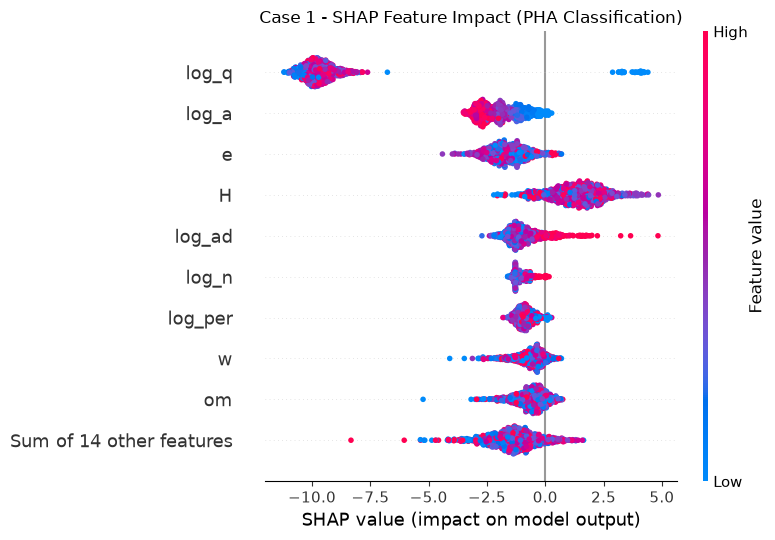

In [ ]:
import matplotlib.pyplot as plt

shap.plots.beeswarm(shap_values_c1,show=False)

plt.title("Case 1 - SHAP Feature Impact (PHA Classification)")

plt.tight_layout()

plt.savefig("results/case1_shap_summary.png",dpi=300,bbox_inches="tight")

plt.show()

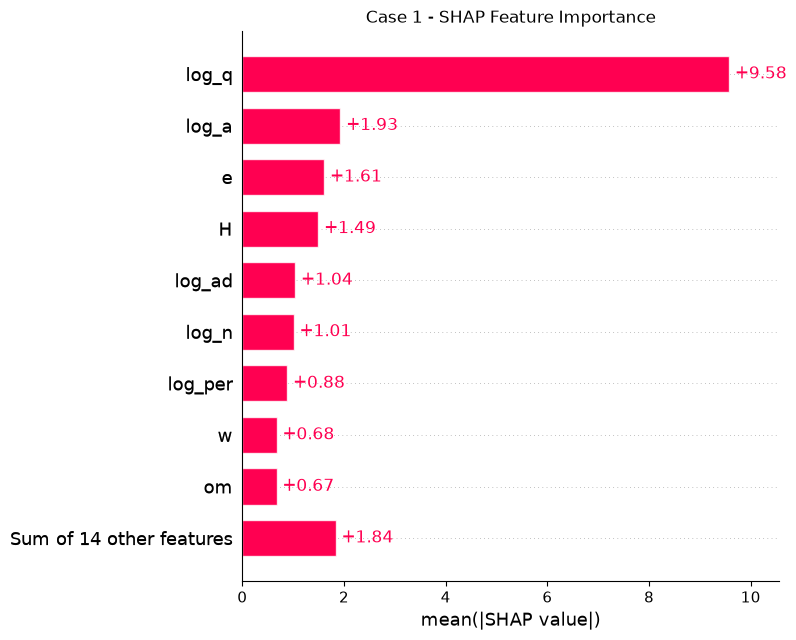

In [ ]:
# case 1-Feature importance
shap.plots.bar(shap_values_c1,show=False)

plt.title("Case 1 - SHAP Feature Importance")

plt.tight_layout()

plt.savefig("results/case1_shap_importance.png",dpi=300,bbox_inches="tight")

plt.show()

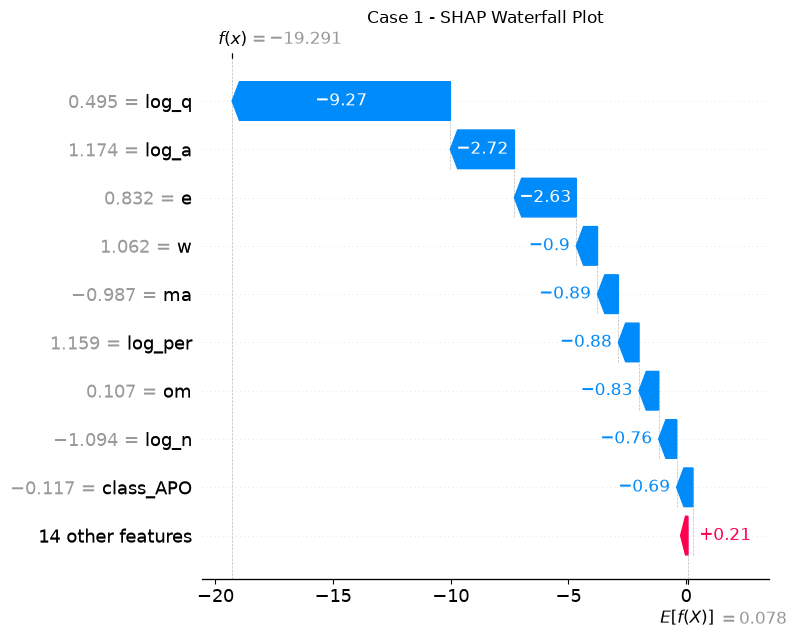

In [ ]:
#Case 1 - Waterfall plot
shap.plots.waterfall(shap_values_c1[0],show=False)

plt.title("Case 1 - SHAP Waterfall Plot")

plt.tight_layout()

plt.savefig("results/case1_shap_waterfall.png",dpi=300,bbox_inches="tight")

plt.show()

In [ ]:
# Load saved Case 2 model
reg = joblib.load("saved_models/best_case2_diameter_regressor.joblib")

print("[LOADED] Case 2 model successfully")

c:\Users\Lenovo\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[LOADED] Case 2 model successfully


In [ ]:
X_test_c2 = pd.read_csv("processed_regression/X_test.csv")

print("X_test shape:", X_test_c2.shape)
print(X_test_c2.head())

X_test shape: (27242, 22)
          e         i         H        om         w        ma     log_a  \
0 -1.290734 -0.635828 -0.392888  1.013371  0.327894 -0.937315 -1.142565   
1 -0.723779  0.020640 -1.419116 -0.113786  0.054668  1.238950  0.437156   
2  0.126708 -1.021413 -0.026379  1.308697 -1.641727 -1.186609 -1.522567   
3  0.383770 -0.201755 -0.539492  1.382456  0.422954  1.046798  0.770277   
4  0.433934 -1.155728  0.560037 -0.618337  0.108285  0.084924 -0.910011   

      log_q    log_ad   log_per  ...  class_APO  class_AST  class_ATE  \
0 -0.384382 -1.621824 -1.174815  ...  -0.059623  -0.008015  -0.025892   
1  0.712113  0.132079  0.461499  ...  -0.059623  -0.008015  -0.025892   
2 -1.300726 -1.424261 -1.587283  ...  -0.059623  -0.008015  -0.025892   
3  0.462438  0.923506  0.792798  ...  -0.059623  -0.008015  -0.025892   
4 -0.938076 -0.703549 -0.926348  ...  -0.059623  -0.008015  -0.025892   

   class_CEN  class_IMB  class_MBA  class_MCA  class_OMB  class_TJN  class_TNO  
0  

Create SHAP explainer

In [ ]:
import shap

explainer = shap.TreeExplainer(reg)

# Take 1000 test rows for faster SHAP calculation
X_sample_c2 = X_test_c2.sample(n=1000,random_state=42)
shap_values_c2 = explainer(X_sample_c2)

print("[SUCCESS] SHAP values calculated")
print("Sample shape:", X_sample_c2.shape)

[SUCCESS] SHAP values calculated
Sample shape: (1000, 22)


Case 2 - SHAP Beeswarm plot

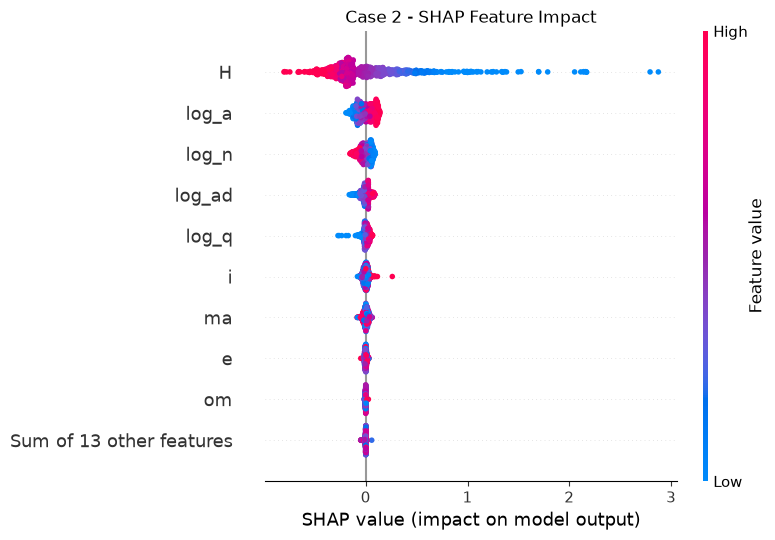

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

shap.plots.beeswarm(shap_values_c2,show=False)
plt.title("Case 2 - SHAP Feature Impact")
plt.tight_layout()
plt.savefig("results/case2_shap_summary.png",dpi=300,bbox_inches="tight")
plt.show()

Case 2 - SHAP Feature Importance

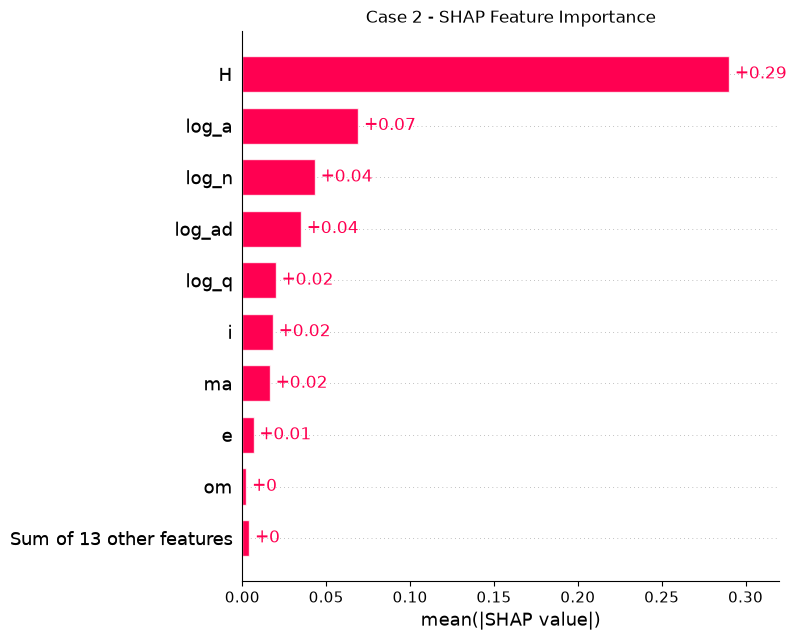

In [7]:
plt.figure(figsize=(10, 6))

shap.plots.bar(shap_values_c2,show=False)

plt.title("Case 2 - SHAP Feature Importance")

plt.tight_layout()

plt.savefig("results/case2_shap_importance.png",dpi=300,bbox_inches="tight")

plt.show()

Case 2 - Waterfall plot

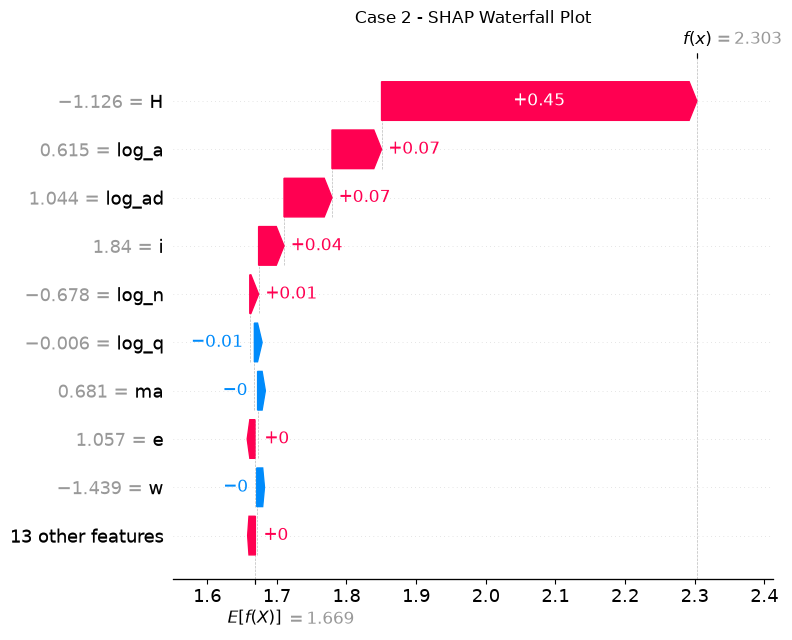

In [ ]:
plt.figure(figsize=(10, 6))

shap.plots.waterfall(shap_values_c2[0],show=False)

plt.title("Case 2 - SHAP Waterfall Plot")s

plt.tight_layout()

plt.savefig("results/case2_shap_waterfall.png",dpi=300,bbox_inches="tight")

plt.show()